# MVP 2 de SSD — Onde e como abrir uma nova unidade de data center

**Disciplina:** Sistemas de Suporte à Decisão — Universidade de Brasília (UnB)
**Aluno:** Lucas Vilas Boas Iwano — 221021017

---

## 1. O problema de decisão

Uma empresa de armazenamento em nuvem vai abrir uma nova unidade e precisa escolher **quatro coisas antes de ligar o primeiro servidor**:

| Decisão | Coluna | Opções |
|---|---|---|
| Região | `datacenter_region` | EU, NA, APAC, ME |
| Perfil de servidor | `server_type` | Compute, GPU, Storage, Edge |
| Refrigeração | `cooling_type` | Air, Liquid, Hybrid |
| Fonte de energia | `energy_source_primary` | Grid, Wind, Hydro, Solar |

São 4 × 4 × 3 × 4 = **192 configurações possíveis**. Cada uma pode ser avaliada por quatro critérios:

| Critério | Pergunta | Variável |
|---|---|---|
| **Risco** | Qual a chance de a unidade operar em risco *Alto* de falha? | `failure_risk_level` |
| **Custo** | Quanto custa computar nessa configuração? | `compute_cost_usd` |
| **Sustentabilidade** | Quanto carbono ela emite? | `carbon_emission_kg` |
| **Tempo** | Por quantos anos ela permanece dentro de um risco aceitável? | `server_age_years` |

### Abordagem adotada neste trabalho

1. **Três modelos preditivos**, um por critério (risco, custo, carbono), usando **somente as decisões de projeto** como entrada. Telemetria de operação (temperaturas, utilização etc.) não existe antes da construção e por isso não entra como preditor.
2. **Simulação das 192 configurações** nos três modelos.
3. **Decisão multicritério** com *score* ponderado, fronteira de Pareto em três dimensões e **análise de sensibilidade sobre todo o espaço de pesos** — a recomendação não depende de um único palpite de peso.
4. **Cronograma de renovação** da configuração recomendada, com base na curva de risco por idade.

## 2. Ambiente

In [1]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             balanced_accuracy_score, r2_score, mean_absolute_error)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 2210
rng = np.random.default_rng(SEED)

try:
    from google.colab import files
    NO_COLAB = True
except ImportError:
    NO_COLAB = False
print("Ambiente pronto. Colab:", NO_COLAB)

Ambiente pronto. Colab: False


## 3. Dados

Base: *Hyperscale Data Center Dataset* (`green_ai_datacenter.csv`, Kaggle) — 100.000 registros de telemetria e 35 colunas.

> **Atenção à leitura do CSV.** A coluna `datacenter_region` usa a sigla `NA` (América do Norte), que o pandas interpreta por padrão como valor nulo. Ler o arquivo com `pd.read_csv(caminho)` faz a região desaparecer silenciosamente. Por isso a leitura abaixo usa `keep_default_na=False`, e o notebook confere logo em seguida que nenhuma região foi perdida.

In [2]:
CSV = "green_ai_datacenter.csv"
if not Path(CSV).exists() and NO_COLAB:
    print("Faça upload de green_ai_datacenter.csv:")
    files.upload()

df = pd.read_csv(CSV, keep_default_na=False, na_values=[""])
print("Dimensões:", df.shape)
print("Nulos totais:", int(df.isna().sum().sum()), "| Duplicatas:", int(df.duplicated().sum()))
print("Regiões:", df["datacenter_region"].value_counts().to_dict())
assert "NA" in set(df["datacenter_region"]), "América do Norte foi perdida na leitura!"
df.head(3)

Dimensões: (100000, 35)


Nulos totais: 0 | Duplicatas: 0
Regiões: {'EU': 37972, 'NA': 28801, 'APAC': 27133, 'ME': 6094}


,server_type,cooling_type,datacenter_region,time_of_day,maintenance_status,energy_source_primary,server_age_years,rack_u_position,workload_intensity,cpu_utilization,...,ups_battery_health,power_consumption_kw,pue,wue,carbon_intensity_gco2_kwh,renewable_energy_ratio,carbon_emission_kg,compute_cost_usd,energy_efficiency_class,failure_risk_level
0,Edge,Air,EU,Night,Normal,Solar,8,38,0.615,46.498,...,63.263,61.939,1.137,0.268,177.167,0.893,1.340,14.090,High,Medium
1,GPU,Liquid,EU,Off-Peak,Normal,Solar,2,17,0.295,21.285,...,88.992,206.840,1.050,2.353,198.353,0.723,11.935,43.436,High,Low
2,Compute,Hybrid,ME,Peak,Normal,Grid,3,1,0.683,52.201,...,78.130,96.127,1.050,0.220,444.571,0.015,44.217,10.093,Low,Low


### 3.1 Sanidade física e redundâncias

Antes de modelar, três verificações: valores fisicamente impossíveis, colunas que são função exata de outras e rótulos derivados do próprio alvo.

In [3]:
checagens = {
    "PUE < 1 (impossível)": (df["pue"] < 1).sum(),
    "consumo <= 0": (df["power_consumption_kw"] <= 0).sum(),
    "custo <= 0": (df["compute_cost_usd"] <= 0).sum(),
    "eficiência de refrigeração fora de [0,1]": (~df["cooling_efficiency"].between(0, 1)).sum(),
    "fração renovável fora de [0,1]": (~df["renewable_energy_ratio"].between(0, 1)).sum(),
}
print(pd.Series(checagens, name="registros violando"))

# Redundância: eficiência da fonte de alimentação vs idade
r = df["server_age_years"].corr(df["power_supply_efficiency"])
print(f"\ncorr(idade, power_supply_efficiency) = {r:.4f}")

# Rótulo derivado: energy_efficiency_class está associado ao risco?
print("\nRisco por classe de eficiência energética (linha = %):")
display(pd.crosstab(df["energy_efficiency_class"], df["failure_risk_level"], normalize="index").mul(100).round(1))

PUE < 1 (impossível)                        0
consumo <= 0                                0
custo <= 0                                  0
eficiência de refrigeração fora de [0,1]    0
fração renovável fora de [0,1]              0
Name: registros violando, dtype: int64

corr(idade, power_supply_efficiency) = -1.0000

Risco por classe de eficiência energética (linha = %):


failure_risk_level,High,Low,Medium
energy_efficiency_class,,,
High,3.4,79.5,17.1
Low,36.7,16.6,46.7
Medium,9.1,50.7,40.2


Leitura: a base já vem limpa (nenhuma violação). `power_supply_efficiency` é função exata da idade (correlação −1), então não traz informação nova. `energy_efficiency_class` é um segundo rótulo gerado a partir da mesma telemetria; não é uma decisão de projeto e não estará disponível antes da construção. Ambas ficam **fora** dos modelos.

### 3.2 Alvos e classes

O risco é ordinal: `Low < Medium < High`. O alvo de classificação é o rótulo original; para a decisão, o que importa é a **probabilidade de risco Alto**.

risco
Low       0.493
Medium    0.345
High      0.163

Baseline (sempre 'Low'): acurácia 49.3%, mas detecta 0% dos casos Alto.


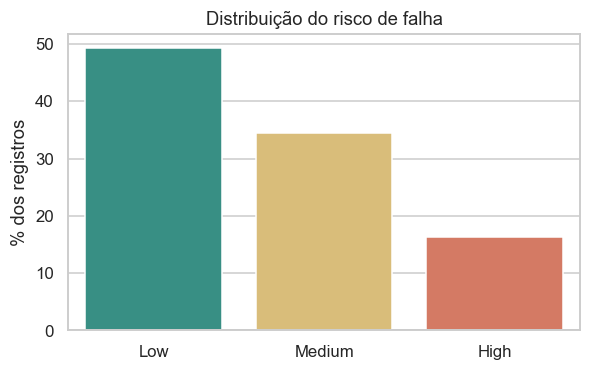

In [4]:
ORDEM_RISCO = ["Low", "Medium", "High"]
df["risco"] = pd.Categorical(df["failure_risk_level"], categories=ORDEM_RISCO, ordered=True)
y_risco = df["risco"].cat.codes

freq = df["risco"].value_counts(normalize=True).reindex(ORDEM_RISCO)
print(freq.round(3).to_string())
print(f"\nBaseline (sempre 'Low'): acurácia {freq.max():.1%}, mas detecta 0% dos casos Alto.")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=freq.index, y=freq.values * 100, palette=["#2a9d8f", "#e9c46a", "#e76f51"], ax=ax)
ax.set(title="Distribuição do risco de falha", xlabel="", ylabel="% dos registros")
plt.show()

## 4. Exploração orientada à decisão

Em vez de olhar a base inteira, as três análises abaixo respondem uma pergunta de decisão cada.

### 4.1 Risco: quais decisões mexem no risco Alto?

A primeira tentativa é olhar a taxa bruta de risco Alto por opção de cada decisão. O resultado parece dizer que APAC, refrigeração a ar, energia da rede e servidores Compute são as escolhas ruins. Antes de aceitar isso, vale checar se esses grupos têm **frotas mais velhas** — e a seção 4.3 mostra que a idade é o que realmente separa os regimes de risco.

% Alto (bruto)  idade média da frota  \
decisão               opção                                           
datacenter_region     APAC               39.5                   7.6   
                      EU                  5.5                   3.7   
                      ME                 11.7                   5.0   
                      NA                  9.5                   5.0   
server_type           Compute            29.1                   6.8   
                      Edge                7.9                   5.0   
                      GPU                 8.3                   3.2   
                      Storage             8.0                   5.0   
cooling_type          Air                24.7                   6.3   
                      Hybrid              9.5                   5.0   
                      Liquid              5.6                   3.5   
energy_source_primary Grid               21.5                   5.9   
                      Hydro               5.6                   3.8   
                      Solar               5.4                   3.8   
                      Wind                5.6                   3.7   

                               % Alto (só idade 8–9)  
decisão               opção                           
datacenter_region     APAC                      39.2  
                      EU                        32.5  
                      ME                        47.1  
                      NA                        36.6  
server_type           Compute                   34.7  
                      Edge                      30.4  
                      GPU                       71.8  
                      Storage                   30.8  
cooling_type          Air                       37.9  
                      Hybrid                    36.7  
                      Liquid                    36.1  
energy_source_primary Grid                      38.7  
                      Hydro                     31.8  
                      Solar                     33.0  
                      Wind                      32.0

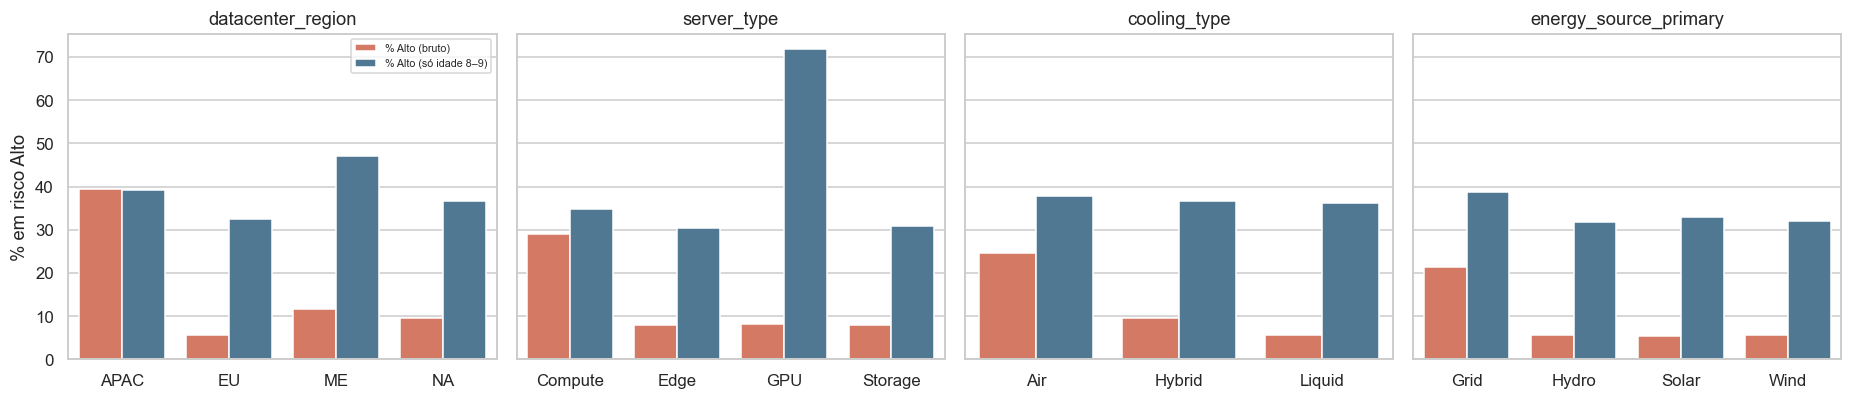

In [5]:
DECISOES = ["datacenter_region", "server_type", "cooling_type", "energy_source_primary"]
df["alto"] = (df["risco"] == "High").astype(int)

linhas = []
for col in DECISOES:
    for opcao, g in df.groupby(col):
        linhas.append({"decisão": col, "opção": opcao,
                       "% Alto (bruto)": g["alto"].mean() * 100,
                       "idade média da frota": g["server_age_years"].mean(),
                       "% Alto (só idade 8–9)": g.loc[g["server_age_years"].between(8, 9), "alto"].mean() * 100})
ctrl = pd.DataFrame(linhas)
display(ctrl.round(1).set_index(["decisão", "opção"]))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, col in zip(axes, DECISOES):
    t = ctrl[ctrl["decisão"] == col].melt(id_vars="opção", value_vars=["% Alto (bruto)", "% Alto (só idade 8–9)"])
    sns.barplot(data=t, x="opção", y="value", hue="variable", ax=ax, palette=["#e76f51", "#457b9d"])
    ax.set(title=col, xlabel="", ylabel="% em risco Alto" if col == DECISOES[0] else "")
    ax.legend(title="", fontsize=7) if col == DECISOES[0] else ax.legend().remove()
plt.tight_layout(); plt.show()

**Leitura.** Na taxa bruta (vermelho), as diferenças entre opções são grandes; comparando só servidores da **mesma faixa de idade** (azul), elas encolhem muito. Boa parte do que parece "efeito da região ou da refrigeração" é apenas **idade média diferente entre os grupos** (confundimento). A seção 6.3 testa isso formalmente com o modelo.

### 4.2 Custo e carbono: cuidado com o efeito do mix de servidores

Comparar a média de custo por região mistura duas coisas: o efeito da região e o efeito de cada região hospedar tipos de servidor diferentes. A tabela abaixo mostra o custo **dentro de cada tipo de servidor**.

In [6]:
print("Mix de servidores por região (% da região):")
display(pd.crosstab(df["datacenter_region"], df["server_type"], normalize="index").mul(100).round(1))

print("\nCusto médio (USD) por região, dentro de cada tipo de servidor:")
display(df.pivot_table(index="datacenter_region", columns="server_type",
                       values="compute_cost_usd", aggfunc="mean").round(2))

print("\nCarbono médio (kg) por região, dentro de cada tipo de servidor:")
display(df.pivot_table(index="datacenter_region", columns="server_type",
                       values="carbon_emission_kg", aggfunc="mean").round(1))

print("\nEfeito da fonte de energia:")
display(df.groupby("energy_source_primary")[["carbon_intensity_gco2_kwh", "renewable_energy_ratio",
        "carbon_emission_kg", "compute_cost_usd"]].mean().round(2))

Mix de servidores por região (% da região):


server_type,Compute,Edge,GPU,Storage
datacenter_region,,,,
APAC,73.1,4.4,9.1,13.4
EU,18.8,18.0,49.0,14.2
ME,39.1,10.0,20.2,30.8
NA,33.2,25.3,16.7,24.9



Custo médio (USD) por região, dentro de cada tipo de servidor:


server_type,Compute,Edge,GPU,Storage
datacenter_region,,,,
APAC,13.39,5.97,30.49,7.69
EU,22.05,12.37,55.38,15.00
ME,11.25,6.01,30.48,7.75
NA,16.58,9.27,44.97,11.38



Carbono médio (kg) por região, dentro de cada tipo de servidor:


server_type,Compute,Edge,GPU,Storage
datacenter_region,,,,
APAC,58.7,26.2,134.7,33.9
EU,4.4,2.5,11.1,3.0
ME,40.4,21.5,109.7,27.9
NA,19.3,10.8,52.5,13.3



Efeito da fonte de energia:


,carbon_intensity_gco2_kwh,renewable_energy_ratio,carbon_emission_kg,compute_cost_usd
energy_source_primary,,,,
Grid,426.67,0.36,39.02,17.57
Hydro,202.65,0.83,6.21,35.04
Solar,202.33,0.83,6.19,35.37
Wind,202.80,0.83,6.20,35.27


### 4.3 Tempo: como o risco evolui com a idade

Este é o eixo temporal do problema: em que idade a unidade deixa de ser segura.

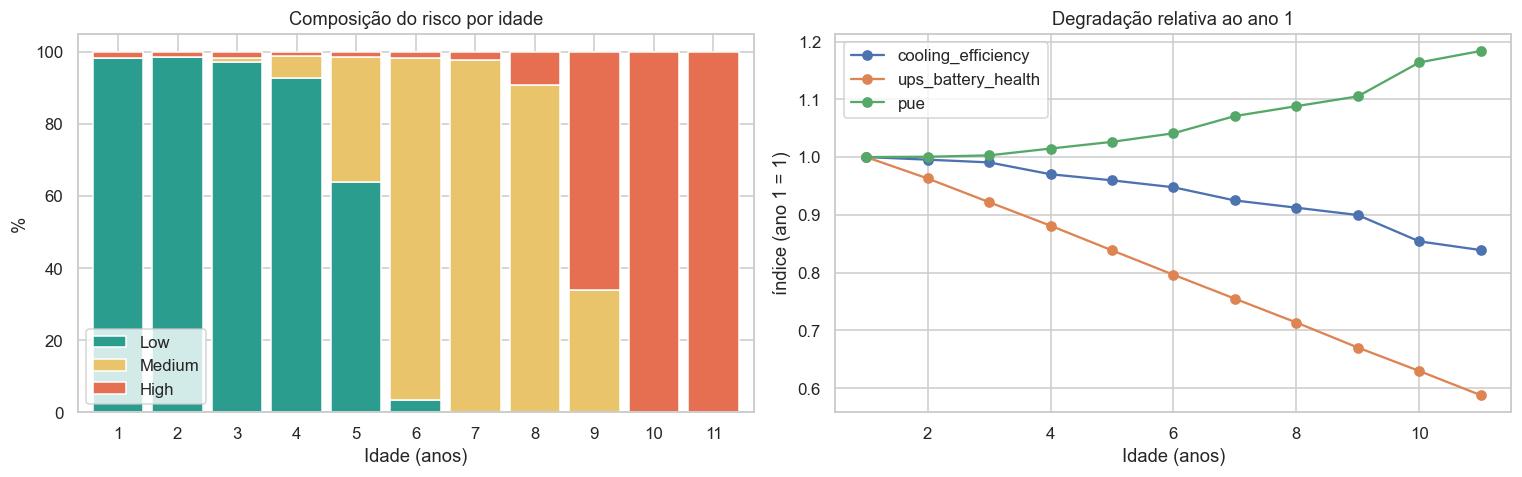

risco,Low,Medium,High
server_age_years,,,
1,98.4,0.0,1.6
2,98.7,0.0,1.3
3,97.1,1.3,1.6
4,92.7,6.0,1.3
5,63.8,34.8,1.4
6,3.3,95.0,1.7
7,0.0,97.6,2.4
8,0.0,90.8,9.2
9,0.0,34.0,66.0


In [7]:
por_idade = pd.crosstab(df["server_age_years"], df["risco"], normalize="index")[ORDEM_RISCO] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
por_idade.plot.bar(stacked=True, ax=axes[0], color=["#2a9d8f", "#e9c46a", "#e76f51"], width=0.85)
axes[0].set(title="Composição do risco por idade", xlabel="Idade (anos)", ylabel="%")
axes[0].legend(title="", loc="lower left"); axes[0].tick_params(axis="x", rotation=0)

deg = df.groupby("server_age_years")[["cooling_efficiency", "ups_battery_health", "pue"]].mean()
(deg / deg.iloc[0]).plot(marker="o", ax=axes[1])
axes[1].set(title="Degradação relativa ao ano 1", xlabel="Idade (anos)", ylabel="índice (ano 1 = 1)")
plt.tight_layout(); plt.show()
display(por_idade.round(1))

## 5. Preparação dos modelos

**Entradas (projeto):** as 4 decisões categóricas + `server_age_years` (horizonte de planejamento). `rack_u_position` foi deixada de fora: é um detalhe de layout interno, não uma decisão de investimento da unidade.

**Alvos:** `risco` (classificação), `compute_cost_usd` e `carbon_emission_kg` (regressões).

A divisão treino/teste é 80/20, **estratificada pelo risco**, e os três modelos usam exatamente as mesmas linhas de treino e teste.

In [8]:
CAT = DECISOES
NUM = ["server_age_years"]
FEATURES = CAT + NUM

X = df[FEATURES]
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, stratify=y_risco, random_state=SEED)

X_tr, X_te = X.loc[idx_tr], X.loc[idx_te]
y_tr, y_te = y_risco.loc[idx_tr], y_risco.loc[idx_te]
print(f"treino: {len(X_tr):,} | teste: {len(X_te):,}")

def prep(escalar=False):
    numerico = StandardScaler() if escalar else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), CAT),
        ("num", numerico, NUM),
    ])

treino: 80,000 | teste: 20,000


## 6. Modelo de risco

Três modelos, todos avaliados por **F1 macro** e **acurácia balanceada** (as classes são desbalanceadas — 49/34/16% — e o erro caro é justamente perder os casos Alto):

1. `DummyClassifier` — piso de referência;
2. Regressão Logística multinomial — modelo linear interpretável;
3. Gradient Boosting em histogramas (`HistGradientBoostingClassifier`) — captura interações entre as decisões.

A comparação usa validação cruzada estratificada (5 folds) **só no treino**; o conjunto de teste fica reservado para a avaliação final.

In [9]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

modelos = {
    "Dummy": Pipeline([("p", prep()), ("m", DummyClassifier(strategy="most_frequent"))]),
    "Regressão Logística": Pipeline([("p", prep(True)), ("m", LogisticRegression(
        max_iter=2000, class_weight="balanced"))]),
    "Gradient Boosting": Pipeline([("p", prep()), ("m", HistGradientBoostingClassifier(
        class_weight="balanced", random_state=SEED))]),
}

linhas = []
for nome, pipe in modelos.items():
    f1 = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    ba = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
    linhas.append({"Modelo": nome, "F1 macro (média)": f1.mean(), "F1 macro (dp)": f1.std(),
                   "Acurácia balanceada": ba.mean()})
comparacao = pd.DataFrame(linhas).set_index("Modelo")
display(comparacao.round(4))

,F1 macro (média),F1 macro (dp),Acurácia balanceada
Modelo,,,
Dummy,0.2200,0.0000,0.3333
Regressão Logística,0.8770,0.0029,0.8913
Gradient Boosting,0.8921,0.0023,0.9019


### 6.1 Ajuste de hiperparâmetros

Busca aleatória (20 combinações, 3 folds) sobre o Gradient Boosting, otimizando F1 macro. A regularização (`min_samples_leaf`, `l2_regularization`) é importante porque as entradas são poucas e discretas, e o modelo poderia memorizar combinações.

In [10]:
busca = RandomizedSearchCV(
    modelos["Gradient Boosting"],
    param_distributions={
        "m__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "m__max_iter": [100, 200, 400],
        "m__max_depth": [3, 4, 6, None],
        "m__min_samples_leaf": [20, 50, 100, 200],
        "m__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    n_iter=20, scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1, refit=True,
)
busca.fit(X_tr, y_tr)
modelo_risco = busca.best_estimator_

print("Melhores parâmetros:", busca.best_params_)
print(f"F1 macro (CV): {busca.best_score_:.4f}")

Melhores parâmetros: {'m__min_samples_leaf': 20, 'm__max_iter': 100, 'm__max_depth': 3, 'm__learning_rate': 0.03, 'm__l2_regularization': 0.0}
F1 macro (CV): 0.8930


### 6.2 Avaliação final no conjunto de teste

,F1 macro,Acurácia balanceada
Regressão Logística,0.8771,0.8930
Gradient Boosting (ajustado),0.8933,0.9039


              precision    recall  f1-score   support

         Low      0.943     0.990     0.966      9850
      Medium      0.961     0.808     0.878      6896
        High      0.770     0.913     0.835      3254

    accuracy                          0.915     20000
   macro avg      0.892     0.904     0.893     20000
weighted avg      0.921     0.915     0.915     20000



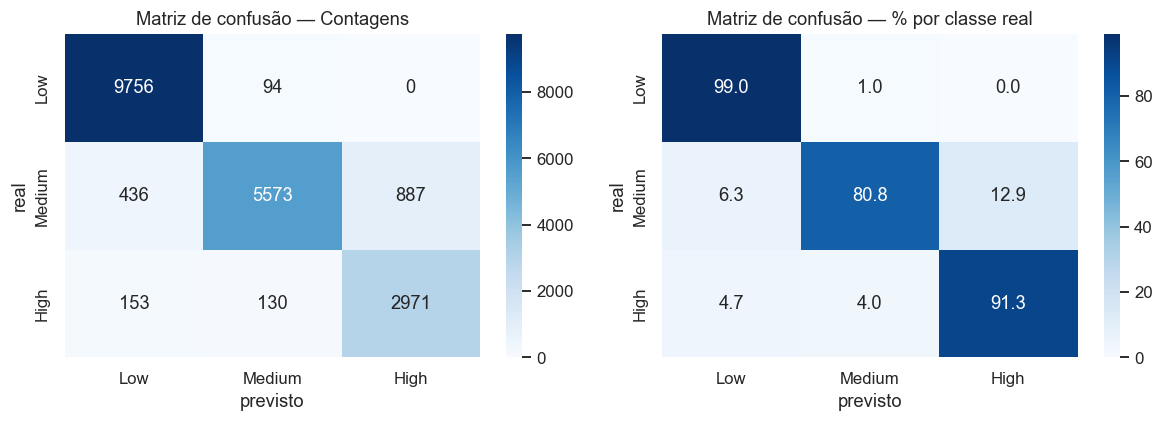

Casos Alto classificados como Low (erro mais grave): 153 de 3254 (4.7%)


Acurácia treino 0.9148 | teste 0.9150


In [11]:
pred = modelo_risco.predict(X_te)
pred_lr = modelos["Regressão Logística"].fit(X_tr, y_tr).predict(X_te)

final = pd.DataFrame({
    "Regressão Logística": [f1_score(y_te, pred_lr, average="macro"), balanced_accuracy_score(y_te, pred_lr)],
    "Gradient Boosting (ajustado)": [f1_score(y_te, pred, average="macro"), balanced_accuracy_score(y_te, pred)],
}, index=["F1 macro", "Acurácia balanceada"]).T
display(final.round(4))

print(classification_report(y_te, pred, target_names=ORDEM_RISCO, digits=3))

cm = confusion_matrix(y_te, pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ORDEM_RISCO, yticklabels=ORDEM_RISCO, ax=axes[0])
sns.heatmap(cm / cm.sum(1, keepdims=True) * 100, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=ORDEM_RISCO, yticklabels=ORDEM_RISCO, ax=axes[1])
for ax, t in zip(axes, ["Contagens", "% por classe real"]):
    ax.set(title=f"Matriz de confusão — {t}", xlabel="previsto", ylabel="real")
plt.tight_layout(); plt.show()

print(f"Casos Alto classificados como Low (erro mais grave): {cm[2, 0]} de {cm[2].sum()} ({cm[2, 0] / cm[2].sum():.1%})")
print(f"Acurácia treino {modelo_risco.score(X_tr, y_tr):.4f} | teste {modelo_risco.score(X_te, y_te):.4f}")

### 6.3 Importância por permutação

Diferente da importância interna de árvores, a importância por permutação mede **quanto o F1 macro cai no teste** ao embaralhar uma decisão inteira. Permutar a coluna original (antes do one-hot) já entrega a importância *por decisão*, sem precisar somar dummies.

,queda_f1,dp
server_age_years,0.5677,0.0045
server_type,0.0446,0.0017
datacenter_region,0.0000,0.0000
cooling_type,0.0000,0.0000
energy_source_primary,0.0000,0.0000


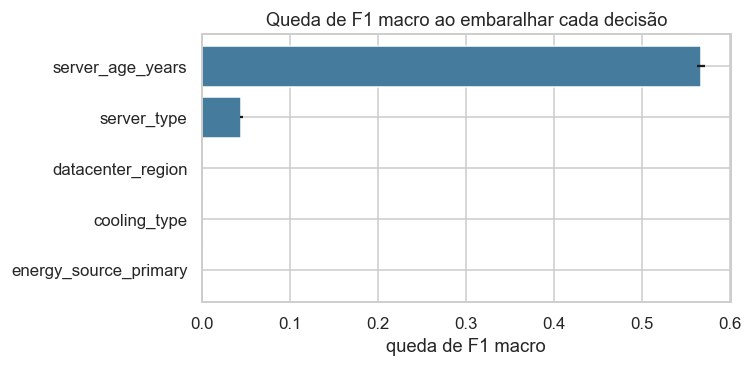

In [12]:
perm = permutation_importance(modelo_risco, X_te, y_te, scoring="f1_macro",
                              n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"queda_f1": perm.importances_mean, "dp": perm.importances_std}, index=FEATURES)\
        .sort_values("queda_f1", ascending=False)
display(imp.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(imp.index[::-1], imp["queda_f1"][::-1], xerr=imp["dp"][::-1], color="#457b9d")
ax.set(title="Queda de F1 macro ao embaralhar cada decisão", xlabel="queda de F1 macro")
plt.tight_layout(); plt.show()

## 7. Modelos de custo e de carbono

Mesmas entradas, mesmo particionamento, dois regressores. Comparação com o baseline "prever a média".

compute_cost_usd     R² = 0.933 | MAE = 3.146 | MAE baseline = 14.646 | redução do erro = 78.5%


carbon_emission_kg   R² = 0.922 | MAE = 5.187 | MAE baseline = 22.890 | redução do erro = 77.3%


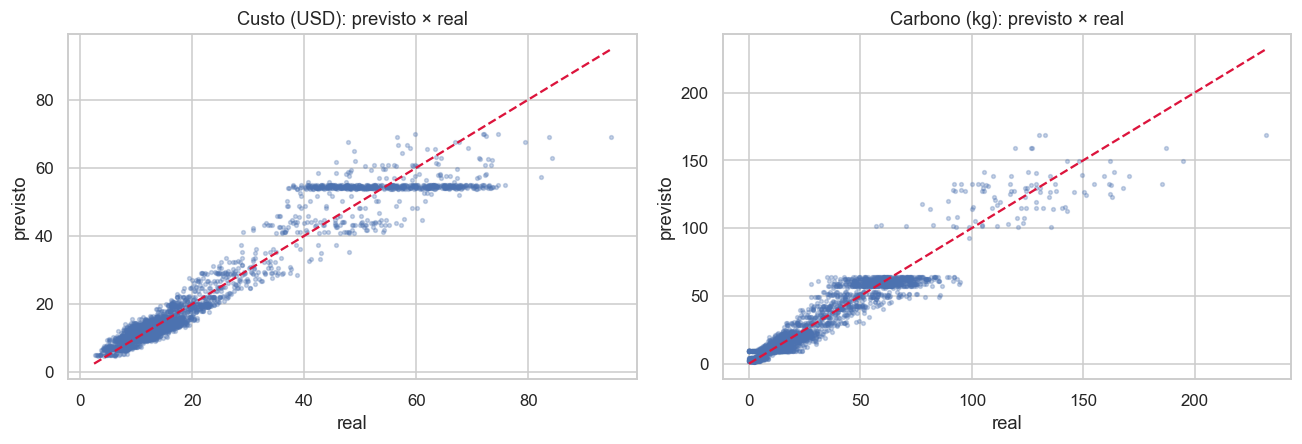

In [13]:
def treinar_regressor(alvo):
    m = Pipeline([("p", prep()), ("m", HistGradientBoostingRegressor(
        learning_rate=0.1, max_iter=300, min_samples_leaf=50, random_state=SEED))])
    m.fit(X_tr, df.loc[idx_tr, alvo])
    p = m.predict(X_te)
    real = df.loc[idx_te, alvo]
    base = mean_absolute_error(real, np.full(len(real), df.loc[idx_tr, alvo].mean()))
    print(f"{alvo:20s} R² = {r2_score(real, p):.3f} | MAE = {mean_absolute_error(real, p):.3f} "
          f"| MAE baseline = {base:.3f} | redução do erro = {1 - mean_absolute_error(real, p) / base:.1%}")
    return m, p, real

modelo_custo, p_custo, r_custo = treinar_regressor("compute_cost_usd")
modelo_carbono, p_carb, r_carb = treinar_regressor("carbon_emission_kg")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (p, r, t) in zip(axes, [(p_custo, r_custo, "Custo (USD)"), (p_carb, r_carb, "Carbono (kg)")]):
    s = rng.choice(len(r), 3000, replace=False)
    ax.scatter(r.iloc[s], p[s], s=6, alpha=0.3)
    lim = [r.min(), r.max()]; ax.plot(lim, lim, "--", color="crimson")
    ax.set(title=f"{t}: previsto × real", xlabel="real", ylabel="previsto")
plt.tight_layout(); plt.show()

> **Como ler o R².** Os modelos de custo e carbono usam só decisões de projeto, então não preveem cada registro individualmente — preveem o **nível esperado da configuração**, que é exatamente o que a decisão de investimento precisa. O erro residual é variação operacional (carga, hora do dia) que ninguém controla no projeto.

## 8. Simulação das 192 configurações

Cada combinação de região × servidor × refrigeração × energia é avaliada nos três modelos, em um **horizonte de planejamento** fixo (parâmetro `HORIZONTE`).

A escolha do horizonte não é neutra. Até o ano 7, o risco Alto é ~1–2% para qualquer configuração (seção 4.3), então avaliar em 5 anos faria todas parecerem iguais em risco. Adota-se **8 anos**: o último ano antes do salto, no qual as configurações começam a se diferenciar. Na seção 8.4 a recomendação é recalculada para outros horizontes.

In [14]:
HORIZONTE = 8

combos = pd.DataFrame(
    list(itertools.product(*[sorted(df[c].unique()) for c in CAT])), columns=CAT
)
combos["server_age_years"] = HORIZONTE

combos["p_alto"] = modelo_risco.predict_proba(combos[FEATURES])[:, 2]
combos["custo_usd"] = modelo_custo.predict(combos[FEATURES])
combos["carbono_kg"] = modelo_carbono.predict(combos[FEATURES])
print(f"{len(combos)} configurações avaliadas (horizonte {HORIZONTE} anos)")
display(combos[["p_alto", "custo_usd", "carbono_kg"]].describe().round(3))

192 configurações avaliadas (horizonte 8 anos)


,p_alto,custo_usd,carbono_kg
count,192.000,192.000,192.000
mean,0.227,19.589,33.758
std,0.243,15.962,38.350
min,0.079,4.958,1.784
25%,0.083,9.118,7.491
50%,0.092,13.420,24.046
75%,0.233,26.883,39.174
max,0.658,69.784,159.273


### 8.1 Fronteira de Pareto em três critérios

Uma configuração está na fronteira se **nenhuma outra é melhor em todos os critérios ao mesmo tempo** (risco, custo e carbono, todos a minimizar). As demais são dominadas e podem ser descartadas sem discussão de preferências.

Na fronteira de Pareto: 6 de 192 (3%) — 186 configurações descartadas sem precisar de pesos.


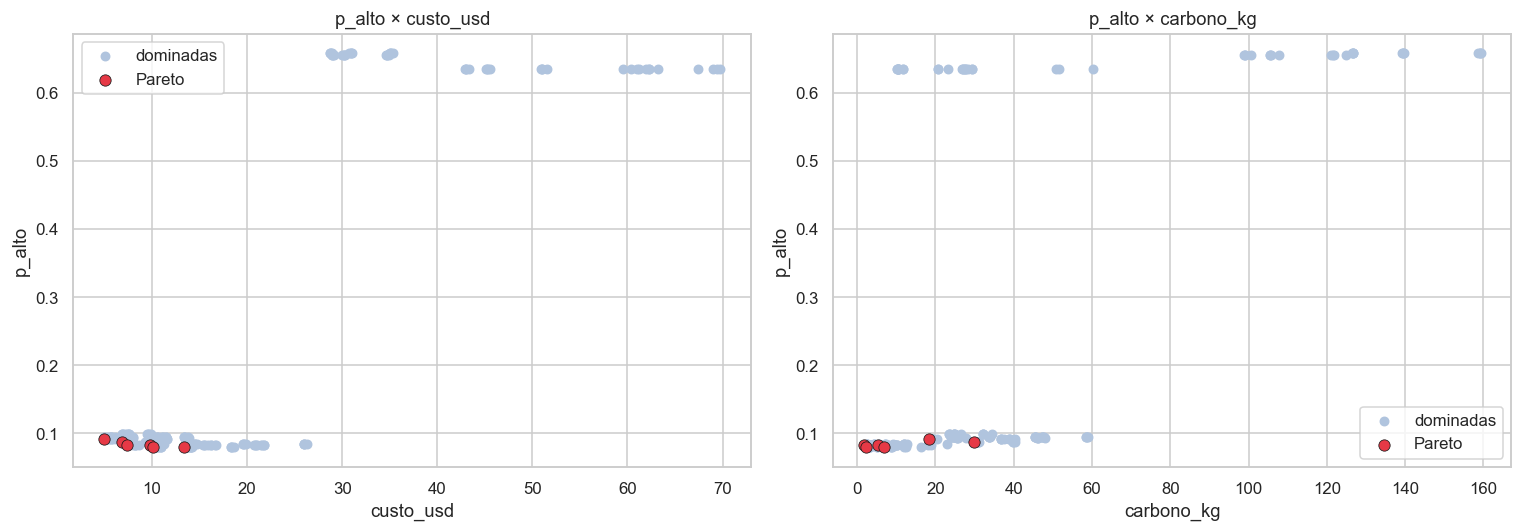

In [15]:
CRITERIOS = ["p_alto", "custo_usd", "carbono_kg"]
M = combos[CRITERIOS].to_numpy()

def nao_dominada(i):
    melhor_ou_igual = (M <= M[i]).all(axis=1)
    estritamente = (M < M[i]).any(axis=1)
    return not (melhor_ou_igual & estritamente).any()

combos["pareto"] = [nao_dominada(i) for i in range(len(M))]
print(f"Na fronteira de Pareto: {combos['pareto'].sum()} de {len(combos)} "
      f"({combos['pareto'].mean():.0%}) — {(~combos['pareto']).sum()} configurações descartadas sem precisar de pesos.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pares = [("custo_usd", "p_alto"), ("carbono_kg", "p_alto")]
for ax, (cx, cy) in zip(axes, pares):
    d, f = combos[~combos["pareto"]], combos[combos["pareto"]]
    ax.scatter(d[cx], d[cy], c="lightsteelblue", s=30, label="dominadas")
    ax.scatter(f[cx], f[cy], c="#e63946", s=55, edgecolor="k", linewidth=0.5, label="Pareto")
    ax.set(xlabel=cx, ylabel=cy, title=f"{cy} × {cx}")
    ax.legend()
plt.tight_layout(); plt.show()

### 8.2 Score multicritério

Os três critérios estão em unidades diferentes, então são normalizados para 0–1 (min-max) e combinados por soma ponderada — quanto **menor** o score, melhor. Os pesos são o parâmetro de política da diretoria; aqui parte-se de um perfil **conservador**: risco pesa mais, porque uma falha em nuvem custa contrato e reputação, e não apenas dinheiro.

In [16]:
PESOS = {"p_alto": 0.50, "custo_usd": 0.30, "carbono_kg": 0.20}
assert abs(sum(PESOS.values()) - 1) < 1e-9

N = (combos[CRITERIOS] - combos[CRITERIOS].min()) / (combos[CRITERIOS].max() - combos[CRITERIOS].min())
combos["score"] = sum(PESOS[c] * N[c] for c in CRITERIOS)
ranking = combos.sort_values("score").reset_index(drop=True)

print(f"Pesos: {PESOS}")
display(ranking.head(10)[CAT + CRITERIOS + ["score", "pareto"]].round(3))

rec = ranking.iloc[0]
print("=" * 60)
print("CONFIGURAÇÃO RECOMENDADA (perfil conservador)")
print("=" * 60)
for rotulo, col in [("Região", "datacenter_region"), ("Servidor", "server_type"),
                    ("Refrigeração", "cooling_type"), ("Energia", "energy_source_primary")]:
    print(f"  {rotulo:14s}: {rec[col]}")
print(f"  P(risco Alto) : {rec['p_alto']:.1%}")
print(f"  Custo previsto: USD {rec['custo_usd']:.2f}")
print(f"  Carbono       : {rec['carbono_kg']:.1f} kg")
print(f"  Na fronteira  : {rec['pareto']}")

Pesos: {'p_alto': 0.5, 'custo_usd': 0.3, 'carbono_kg': 0.2}


,datacenter_region,server_type,cooling_type,energy_source_primary,p_alto,custo_usd,carbono_kg,score,pareto
0,NA,Edge,Liquid,Hydro,0.083,7.389,5.218,0.019,True
1,NA,Edge,Liquid,Solar,0.083,7.455,5.218,0.020,False
2,NA,Edge,Hybrid,Solar,0.083,8.182,5.455,0.023,False
3,NA,Edge,Hybrid,Hydro,0.083,8.188,5.455,0.023,False
4,NA,Edge,Liquid,Wind,0.083,8.319,5.339,0.024,False
5,NA,Edge,Liquid,Grid,0.083,7.624,8.920,0.025,False
6,NA,Edge,Hybrid,Wind,0.083,8.645,5.576,0.026,False
7,EU,Edge,Liquid,Hydro,0.083,9.741,1.784,0.026,True
8,EU,Edge,Liquid,Solar,0.083,9.919,1.784,0.027,False
9,NA,Edge,Hybrid,Grid,0.083,8.023,9.253,0.027,False


CONFIGURAÇÃO RECOMENDADA (perfil conservador)
  Região        : NA
  Servidor      : Edge
  Refrigeração  : Liquid
  Energia       : Hydro
  P(risco Alto) : 8.3%
  Custo previsto: USD 7.39
  Carbono       : 5.2 kg
  Na fronteira  : True


#### Restrição de negócio: perfil `Storage`

`server_type` é uma decisão de **perfil de carga**, não uma escolha livre entre alternativas equivalentes: `Edge` e `Compute` atendem outros serviços. Para uma empresa cujo negócio é armazenamento, o ranking global pode recomendar algo que a empresa não vai operar. O ranking abaixo fixa `server_type = Storage` e reaplica os mesmos pesos, com a normalização refeita dentro do subconjunto.

In [17]:
sub = combos[combos["server_type"] == "Storage"].copy()
Ns = (sub[CRITERIOS] - sub[CRITERIOS].min()) / (sub[CRITERIOS].max() - sub[CRITERIOS].min())
sub["score"] = sum(PESOS[c] * Ns[c] for c in CRITERIOS)
rank_storage = sub.sort_values("score").reset_index(drop=True)
display(rank_storage.head(5)[CAT + CRITERIOS + ["score"]].round(3))
rec_storage = rank_storage.iloc[0]
print("Recomendação restrita a Storage:",
      " / ".join(rec_storage[c] for c in ["datacenter_region", "server_type", "cooling_type", "energy_source_primary"]))

,datacenter_region,server_type,cooling_type,energy_source_primary,p_alto,custo_usd,carbono_kg,score
0,NA,Storage,Liquid,Solar,0.079,10.143,6.725,0.107
1,NA,Storage,Liquid,Hydro,0.079,10.266,6.725,0.110
2,NA,Storage,Hybrid,Solar,0.079,10.792,6.944,0.125
3,NA,Storage,Hybrid,Hydro,0.079,10.939,6.944,0.129
4,NA,Storage,Liquid,Grid,0.079,10.200,11.926,0.136


Recomendação restrita a Storage: NA / Storage / Liquid / Solar


### 8.3 Sensibilidade: a recomendação depende dos pesos?

Em vez de testar alguns pesos escolhidos à mão, varremos **todo o simplex de pesos** com passo de 0,05 (231 combinações que somam 1) e registramos qual configuração vence em cada uma. Se poucas configurações dominam a grade, a decisão é robusta; se muitas alternam, a escolha é de fato política.

Combinações de pesos avaliadas: 231

Configurações distintas que vencem em algum ponto da grade: 6 (de 192)


,datacenter_region,server_type,cooling_type,energy_source_primary,p_alto,custo_usd,carbono_kg,% da grade em que vence,pareto
165,NA,Edge,Liquid,Hydro,0.083,7.389,5.218,34.6,True
69,EU,Edge,Liquid,Hydro,0.083,9.741,1.784,30.7,True
118,ME,Edge,Liquid,Solar,0.092,4.958,18.358,23.8,True
93,EU,Storage,Liquid,Hydro,0.079,13.321,2.371,8.2,True
190,NA,Storage,Liquid,Solar,0.079,10.143,6.725,2.2,True
88,EU,Storage,Hybrid,Grid,0.079,14.162,5.131,0.4,False


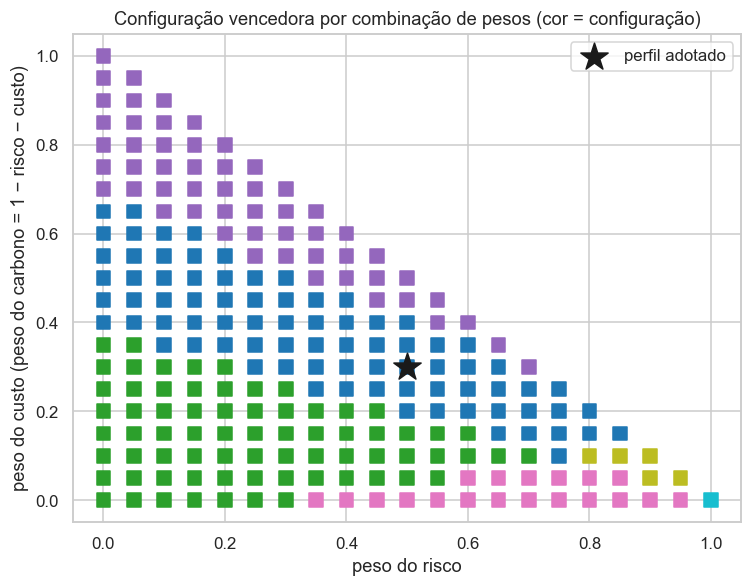

In [18]:
passo = 0.05
grade = [(a, b, round(1 - a - b, 10)) for a in np.arange(0, 1 + 1e-9, passo)
         for b in np.arange(0, 1 - a + 1e-9, passo)]
print("Combinações de pesos avaliadas:", len(grade))

Nn = N.to_numpy()
vencedoras = []
for w in grade:
    vencedoras.append((Nn @ np.array(w)).argmin())

freq_venc = pd.Series(vencedoras).value_counts()
tab = combos.loc[freq_venc.index, CAT + CRITERIOS].copy()
tab["% da grade em que vence"] = (freq_venc.values / len(grade) * 100).round(1)
tab["pareto"] = combos.loc[freq_venc.index, "pareto"]
print(f"\nConfigurações distintas que vencem em algum ponto da grade: {len(tab)} (de 192)")
display(tab.round(3))

# mapa: risco x custo (carbono = resto)
w_r = np.array([w[0] for w in grade]); w_c = np.array([w[1] for w in grade]); w_k = np.array([w[2] for w in grade])
rotulos = {k: i for i, k in enumerate(freq_venc.index)}
cores = [rotulos[v] for v in vencedoras]
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(w_r, w_c, c=cores, cmap="tab10", s=80, marker="s")
ax.scatter([PESOS["p_alto"]], [PESOS["custo_usd"]], marker="*", s=350, c="k", label="perfil adotado")
ax.set(xlabel="peso do risco", ylabel="peso do custo (peso do carbono = 1 − risco − custo)",
       title="Configuração vencedora por combinação de pesos (cor = configuração)")
ax.legend(); plt.tight_layout(); plt.show()

### 8.4 Sensibilidade ao horizonte de planejamento

O horizonte também é um parâmetro de decisão. A tabela mostra a configuração vencedora (pesos adotados) para diferentes horizontes.

In [19]:
def melhor_no_horizonte(h):
    c = combos[CAT].copy(); c["server_age_years"] = h
    t = pd.DataFrame({"p_alto": modelo_risco.predict_proba(c[FEATURES])[:, 2],
                      "custo_usd": modelo_custo.predict(c[FEATURES]),
                      "carbono_kg": modelo_carbono.predict(c[FEATURES])})
    n = (t - t.min()) / (t.max() - t.min())
    s = sum(PESOS[k] * n[k] for k in CRITERIOS)
    i = s.idxmin()
    return {"horizonte": h, **{k: c.loc[i, k] for k in CAT}, **t.loc[i].round(3).to_dict(),
            "amplitude de p_alto entre as 192": round(t["p_alto"].max() - t["p_alto"].min(), 3)}

display(pd.DataFrame([melhor_no_horizonte(h) for h in [3, 5, 7, 8, 9]]).set_index("horizonte"))

,datacenter_region,server_type,cooling_type,energy_source_primary,p_alto,custo_usd,carbono_kg,amplitude de p_alto entre as 192
horizonte,,,,,,,,
3,EU,Storage,Liquid,Hydro,0.031,12.698,2.212,0.028
5,EU,Edge,Liquid,Hydro,0.040,9.425,1.717,0.089
7,NA,Storage,Liquid,Solar,0.042,10.060,6.772,0.050
8,NA,Edge,Liquid,Hydro,0.083,7.389,5.218,0.579
9,NA,Storage,Liquid,Solar,0.744,9.993,6.978,0.188


## 9. Cronograma de renovação

Fixada a configuração recomendada, consulta-se o modelo de risco idade a idade. Definem-se dois marcos:

- **Marco de atenção:** primeira idade em que o risco Médio passa a superar o Baixo — a frota deixa o regime saudável e é hora de orçar a renovação;
- **Marco de renovação:** primeira idade em que P(Alto) supera o limiar de aceitação (`LIMIAR_ALTO`, padrão 30%).

Como o modelo só foi treinado com idades de 1 a 11 anos, **nada é extrapolado além disso**.

,idade,Low,Medium,High,custo_usd,carbono_kg
0,1,0.959,0.005,0.036,7.190,4.823
1,2,0.962,0.005,0.033,7.049,4.839
2,3,0.954,0.012,0.034,7.060,4.878
3,4,0.933,0.033,0.033,7.160,4.992
4,5,0.621,0.338,0.041,7.223,5.002
5,6,0.038,0.921,0.041,7.624,5.024
6,7,0.007,0.948,0.045,7.825,5.185
7,8,0.007,0.910,0.083,7.389,5.218
8,9,0.010,0.234,0.755,7.238,5.397
9,10,0.001,0.002,0.997,7.238,5.397


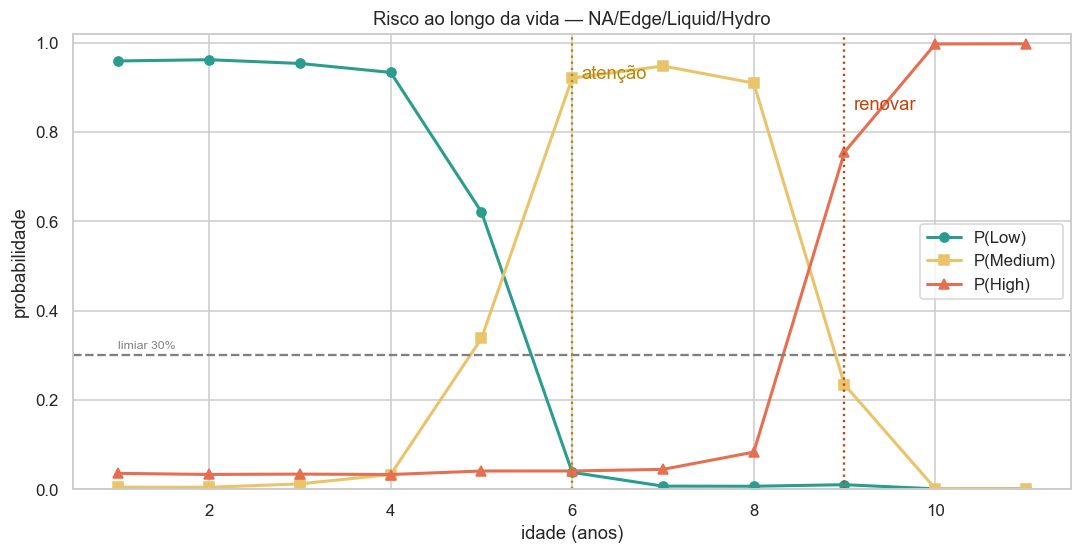

CRONOGRAMA
  Marco de atenção  : ano 6
  Marco de renovação: ano 9


In [20]:
LIMIAR_ALTO = 0.30

idades = np.arange(df["server_age_years"].min(), df["server_age_years"].max() + 1)
proj = pd.DataFrame({c: rec[c] for c in CAT}, index=range(len(idades)))
proj["server_age_years"] = idades

pr = modelo_risco.predict_proba(proj[FEATURES])
curva = pd.DataFrame(pr, columns=ORDEM_RISCO)
curva.insert(0, "idade", idades)
curva["custo_usd"] = modelo_custo.predict(proj[FEATURES])
curva["carbono_kg"] = modelo_carbono.predict(proj[FEATURES])
display(curva.round(3))

ano_atencao = curva.loc[curva["Medium"] > curva["Low"], "idade"].min()
ano_renov = curva.loc[curva["High"] > LIMIAR_ALTO, "idade"].min()
ano_atencao = None if pd.isna(ano_atencao) else int(ano_atencao)
ano_renov = None if pd.isna(ano_renov) else int(ano_renov)

fig, ax = plt.subplots(figsize=(10, 5.2))
for col, cor, mk in [("Low", "#2a9d8f", "o"), ("Medium", "#e9c46a", "s"), ("High", "#e76f51", "^")]:
    ax.plot(curva["idade"], curva[col], marker=mk, color=cor, lw=2, label=f"P({col})")
ax.axhline(LIMIAR_ALTO, ls="--", c="gray"); ax.text(idades[0], LIMIAR_ALTO + 0.015, f"limiar {LIMIAR_ALTO:.0%}", color="gray", fontsize=8)
if ano_atencao: ax.axvline(ano_atencao, ls=":", c="#b8860b"); ax.text(ano_atencao + .1, .92, "atenção", color="#b8860b")
if ano_renov: ax.axvline(ano_renov, ls=":", c="#c1440e"); ax.text(ano_renov + .1, .85, "renovar", color="#c1440e")
ax.set(title=f"Risco ao longo da vida — {rec['datacenter_region']}/{rec['server_type']}/{rec['cooling_type']}/{rec['energy_source_primary']}",
       xlabel="idade (anos)", ylabel="probabilidade", ylim=(0, 1.02))
ax.legend(); plt.tight_layout(); plt.show()

print("CRONOGRAMA")
print(f"  Marco de atenção  : {'ano ' + str(ano_atencao) if ano_atencao else 'não atingido em 1–11 anos'}")
print(f"  Marco de renovação: {'ano ' + str(ano_renov) if ano_renov else 'não atingido em 1–11 anos'}")

## 10. Conclusão

Este MVP tratou a abertura de uma nova unidade como um problema de **decisão multicritério** (risco, custo, carbono e tempo), com três modelos preditivos alimentados apenas por decisões de projeto e uma simulação das 192 configurações possíveis.

### O que os dados mostram

1. **O risco é, essencialmente, uma questão de idade.** O risco Alto fica em 1–2% até o ano 7, sobe para 9% no ano 8, 66% no ano 9 e chega a 100% nos anos 10 e 11. Na importância por permutação, embaralhar `server_age_years` derruba o F1 macro em cerca de 0,57; `server_type` derruba cerca de 0,04; região, refrigeração e energia praticamente não alteram o resultado.
2. **A taxa bruta de risco engana por confundimento.** APAC (39,5%), refrigeração a ar (24,7%) e energia da rede (21,5%) parecem as piores opções, mas são os grupos de frota mais velha (idade média 7,6, 6,3 e 5,9 anos contra 3,5–3,8 das opções "boas"). Comparando apenas idades 8–9, as diferenças caem bastante (por exemplo, refrigeração: 36–38% nas três opções). Conclusão prática: **trocar de região ou de refrigeração não reduz o risco por si só; o que reduz o risco é renovar a tempo**. A exceção nítida é o tipo de servidor: **GPU** chega ao ponto crítico um ano antes (72% de risco Alto nas idades 8–9, contra 30–35% dos demais).
3. **Custo e carbono, sim, dependem das decisões de projeto.** A fonte de energia separa as emissões em cerca de 6 kg (Hydro/Solar/Wind) contra 39 kg (Grid), enquanto o custo computacional médio das fontes renováveis é cerca do dobro (USD 35 contra 17,6; média bruta, influenciada pelo mix de servidores). A região muda a emissão em ordem de grandeza: para o mesmo tipo de servidor, a EU emite cerca de 4,4 kg contra 58,7 kg da APAC (Compute). O efeito é real, pois persiste dentro de cada tipo de servidor.
4. **Modelos.** O Gradient Boosting ajustado atinge F1 macro de 0,893 no teste (regressão logística: 0,877; baseline: 0,22), com apenas 4,7% dos casos Alto classificados como Baixo e sem sinal de overfitting (acurácia 0,915 no treino e no teste). Os modelos de custo e carbono explicam R² de 0,93 e 0,92.

### O que a decisão recomenda

5. **Configuração global (pesos 50% risco / 30% custo / 20% carbono, horizonte de 8 anos):** NA / Edge / Liquid / Hydro, com P(Alto) de 8,3%, custo previsto de USD 7,39 e 5,2 kg de carbono. Está na fronteira de Pareto, que tem apenas 6 das 192 configurações.
6. **A recomendação é estável em três dimensões, e sensível em duas.** Refrigeração líquida e energia hídrica ou solar aparecem em 5 das 6 vencedoras (a exceção, Hybrid/Grid, vence em apenas 0,4% da grade); sensíveis são a **região** (NA, EU ou ME conforme o peso dado a custo e carbono) e o **horizonte** (com 5 anos, a vencedora passa a ser EU/Edge/Liquid/Hydro). Apenas 6 configurações vencem em algum ponto de toda a grade de 231 pesos, o que torna a escolha final uma questão de política da diretoria entre poucas alternativas, e não uma busca em 192.
7. **Restrição de negócio.** Como a empresa é de armazenamento, a recomendação global em servidor Edge não é necessariamente operável. O ranking restrito a `Storage` (seção 8.2) recomenda **NA / Storage / Liquid / Solar**, e essa é a leitura mais aderente ao negócio.

### Cronograma

8. Para a configuração recomendada: **ano 6** — o risco Médio passa a superar o Baixo (iniciar orçamento e homologação de fornecedores); **ano 9** — P(Alto) ultrapassa o limiar de 30% (executar a renovação da frota). A janela de operação plenamente segura é de 8 anos.

### Limitações

- A base é **sintética**: as relações refletem o processo que a gerou, em especial o salto de risco entre os anos 8 e 10, que é muito mais abrupto do que o desgaste real de equipamentos. Os resultados não substituem dados operacionais reais.
- As idades 10 e 11 existem só em parte das combinações (Compute/Air/APAC), o que limita a comparação entre configurações nesses anos.
- `compute_cost_usd` é custo computacional por registro, não CAPEX. Não há terreno, obra ou licenças na base, então o eixo custo cobre a operação, não o investimento inicial.
- A base não tem prazo de obra; o eixo "tempo" foi tratado como ciclo de vida da unidade.
- As regiões são agregados continentais; a escolha de um país ou cidade exige dados locais de energia, conectividade e regulação (LGPD, GDPR, soberania de dados).
- Os pesos do score são um parâmetro de política; a sensibilidade mostra o efeito, mas não define o valor correto.

### Próximos passos

- incorporar CAPEX e cronograma de obra para completar os eixos de custo e tempo;
- aplicar restrições regulatórias como filtro sobre as candidatas;
- calibrar as probabilidades do modelo de risco antes de usá-las como probabilidades absolutas;
- estender a simulação para uma carteira de várias unidades.

---

**Aluno:** Lucas Vilas Boas Iwano — **Matrícula:** 221021017
**Disciplina:** Sistemas de Suporte à Decisão — Universidade de Brasília (UnB)